In [1]:
from pathlib import Path

import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

qc_table_path = (
    project_root / "results" / "tables" / "cell_qc_metadata.csv"
)

qc_metadata = pd.read_csv(
    qc_table_path,
    index_col="cell_id",
    dtype={"Lane": str},
)

print("QC table shape:", qc_metadata.shape)

qc_metadata.head(3)

QC table shape: (30676, 7)


,Donor,condition,Lane,total_counts,n_genes_by_counts,total_counts_mt,pct_counts_mt
cell_id,,,,,,,
AAACCTGCACGTCTCT,UKERi1E4-R1-003,Control,1,17378.0,3771,655.0,3.769133
AAACCTGCAGTATCTG,UKERiO3H-R1-005,Control,1,13234.0,3823,210.0,1.586822
AAACCTGTCCAGTATG,UKERi88H-R1-002,Parkinson,1,19998.0,4622,239.0,1.195119


In [2]:
import anndata as ad

data_path = (
    project_root
    / "data"
    / "raw"
    / "GSE176160_ipsc_ipd_patients_raw.h5ad"
)

adata = ad.read_h5ad(data_path, backed="r")

print("AnnData shape:", adata.shape)
print("QC table shape:", qc_metadata.shape)

assert qc_metadata.index.is_unique, "Duplicate cell IDs in the QC table."

assert qc_metadata.index.astype(str).equals(
    adata.obs_names.astype(str)
), "Cell IDs or their order differ between the two inputs."

print("Cell IDs and order verified.")

AnnData shape: (30676, 58735)
QC table shape: (30676, 7)
Cell IDs and order verified.


In [3]:
min_detected_genes = 1000
mitochondrial_cutoff_pct = 15.0

qc_metadata["low_genes"] = qc_metadata["n_genes_by_counts"].lt(
    min_detected_genes
)

qc_metadata["high_mt"] = qc_metadata["pct_counts_mt"].ge(
    mitochondrial_cutoff_pct
)

qc_metadata["preliminary_qc_flag"] = (
    qc_metadata["low_genes"] | qc_metadata["high_mt"]
)

flag_columns = ["low_genes", "high_mt", "preliminary_qc_flag"]
qc_metadata[flag_columns].sum().rename("n_cells")

low_genes              25
high_mt                67
preliminary_qc_flag    87
Name: n_cells, dtype: int64

In [4]:
from scipy import sparse

pilot_lane = "1"
pilot_lane_mask = (
    adata.obs["Lane"].astype(str).eq(pilot_lane).to_numpy()
)

pilot_count_chunks = []

for counts_chunk, start, stop in adata.chunked_X(chunk_size=256):
    rows_in_pilot_lane = pilot_lane_mask[start:stop]

    if rows_in_pilot_lane.any():
        selected_counts = counts_chunk[rows_in_pilot_lane, :]
        pilot_count_chunks.append(sparse.csr_matrix(selected_counts))

pilot_counts = sparse.vstack(pilot_count_chunks, format="csr")
pilot_cell_ids = adata.obs_names[pilot_lane_mask]

assert pilot_counts.shape == (len(pilot_cell_ids), adata.n_vars)

print("Pilot lane:", pilot_lane)
print("Count matrix shape:", pilot_counts.shape)
print("Matrix format:", pilot_counts.format)

Pilot lane: 1
Count matrix shape: (4829, 58735)
Matrix format: csr


In [5]:
from importlib.metadata import version

import scanpy as sc

print("Scanpy version:", version("scanpy"))
print("Scrublet available:", callable(sc.pp.scrublet))

Scanpy version: 1.12.5
Scrublet available: True


In [6]:
pilot_adata = ad.AnnData(
    X=pilot_counts,
    obs=pd.DataFrame(index=pilot_cell_ids),
    var=pd.DataFrame(index=adata.var_names),
)

sc.pp.scrublet(
    pilot_adata,
    expected_doublet_rate=0.05,
    threshold=None,
    random_state=0,
)

print("Scored cells:", pilot_adata.n_obs)
print("\nAutomatic doublet calls:")
print(pilot_adata.obs["predicted_doublet"].value_counts())

pilot_adata.obs["doublet_score"].describe()

Scored cells: 4829

Automatic doublet calls:
predicted_doublet
False    4826
True        3
Name: count, dtype: int64


count    4829.000000
mean        0.049763
std         0.041002
min         0.002706
25%         0.026112
50%         0.040640
75%         0.060606
max         0.580110
Name: doublet_score, dtype: float64

Automatic threshold: 0.5284083863185415


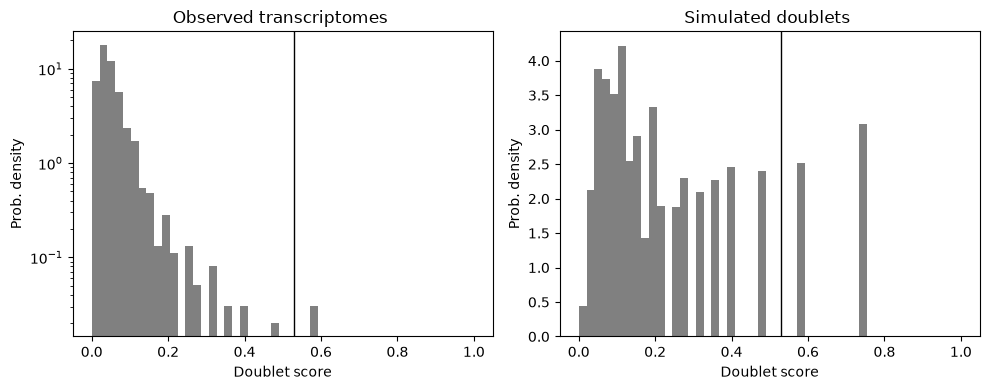

In [7]:
pilot_threshold = pilot_adata.uns["scrublet"].get("threshold")
print("Automatic threshold:", pilot_threshold)

sc.pl.scrublet_score_distribution(
    pilot_adata,
    figsize=(10, 4),
)

In [8]:
pilot_scores = pilot_adata.obs[
    ["doublet_score", "predicted_doublet"]
]

pilot_qc_review = qc_metadata.loc[pilot_scores.index].join(
    pilot_scores,
    validate="one_to_one",
)

review_columns = [
    "Donor",
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_mt",
    "preliminary_qc_flag",
    "doublet_score",
    "predicted_doublet",
]

pilot_qc_review.nlargest(10, "doublet_score")[review_columns].round(
    {"pct_counts_mt": 2, "doublet_score": 3}
)

,Donor,total_counts,n_genes_by_counts,pct_counts_mt,preliminary_qc_flag,doublet_score,predicted_doublet
cell_id,,,,,,,
AACGTTGCATTTCACT,UKERi1E4-R1-003,24934.0,5376,2.98,False,0.580,True
CTGTTTAAGCAGACTG,UKERiC99-R1-007,35538.0,6314,2.88,False,0.580,True
TGGTTCCGTTGAGTTC,UKERi1E4-R1-003,18695.0,4648,1.47,False,0.580,True
ACCCACTTCAGGCGAA,UKERi88H-R1-002,27165.0,5751,3.60,False,0.477,False
ACGCAGCAGCTAGCCC,UKERiM89-R1-005,27784.0,5700,2.22,False,0.477,False
GACTACACATCAGTAC,UKERiC99-R1-007,22518.0,5334,2.40,False,0.404,False
GGCAATTTCTGTCTAT,UKERiJ2C-R1-015,21353.0,4760,5.02,False,0.404,False
TGGCGCAAGCGTTCCG,UKERi1E4-R1-003,29771.0,5886,2.13,False,0.404,False
ATGGGAGCATTTCAGG,UKERiPX7-R1-001,10862.0,3343,0.81,False,0.349,False


In [9]:
def run_scrublet_for_lane(adata, lane):
    lane_mask = adata.obs["Lane"].astype(str).eq(lane).to_numpy()
    count_chunks = []

    for counts_chunk, start, stop in adata.chunked_X(chunk_size=256):
        rows_in_lane = lane_mask[start:stop]

        if rows_in_lane.any():
            selected_counts = counts_chunk[rows_in_lane, :]
            count_chunks.append(sparse.csr_matrix(selected_counts))

    lane_adata = ad.AnnData(
        X=sparse.vstack(count_chunks, format="csr"),
        obs=pd.DataFrame(index=adata.obs_names[lane_mask]),
        var=pd.DataFrame(index=adata.var_names),
    )

    sc.pp.scrublet(
        lane_adata,
        expected_doublet_rate=0.05,
        threshold=None,
        random_state=0,
    )

    return lane_adata


lane_2_adata = run_scrublet_for_lane(adata, "2")

print("Scored cells:", lane_2_adata.n_obs)
print("Automatic threshold:", lane_2_adata.uns["scrublet"].get("threshold"))
print(lane_2_adata.obs["predicted_doublet"].value_counts())

Scored cells: 4935
Automatic threshold: 0.5259933237478827
predicted_doublet
False    4933
True        2
Name: count, dtype: int64


In [10]:
score_columns = ["doublet_score", "predicted_doublet"]

scores_by_lane = {
    "1": pilot_adata.obs[score_columns].copy(),
    "2": lane_2_adata.obs[score_columns].copy(),
}

diagnostics_by_lane = {
    "1": pilot_adata.uns["scrublet"],
    "2": lane_2_adata.uns["scrublet"],
}

for lane in ["3", "4", "5", "6"]:
    print(f"\nScoring Lane {lane}")

    lane_result = run_scrublet_for_lane(adata, lane)

    scores_by_lane[lane] = lane_result.obs[score_columns].copy()
    diagnostics_by_lane[lane] = lane_result.uns["scrublet"]

    threshold = diagnostics_by_lane[lane].get("threshold")

    print("Scored cells:", lane_result.n_obs)
    print("Automatic threshold:", threshold)

    if threshold is None:
        print("Automatic doublet calls: unavailable")
    else:
        print(
            "Flagged cells:",
            scores_by_lane[lane]["predicted_doublet"].sum(),
        )

    del lane_result


Scoring Lane 3
Scored cells: 5139
Automatic threshold: 0.5353804944524456
Flagged cells: 1

Scoring Lane 4
Scored cells: 5169
Automatic threshold: 0.5329531152600495
Flagged cells: 0

Scoring Lane 5
Scored cells: 5302
Automatic threshold: 0.5330500027880017
Flagged cells: 3

Scoring Lane 6
Scored cells: 5302
Automatic threshold: 0.5353804944524456
Flagged cells: 4


In [11]:
doublet_scores = pd.concat(
    list(scores_by_lane.values()),
    verify_integrity=True,
)

assert len(doublet_scores) == len(qc_metadata), (
    "The score table does not cover all input cells."
)

assert doublet_scores.index.isin(qc_metadata.index).all(), (
    "The score table contains unknown cell IDs."
)

assert doublet_scores.notna().all().all(), (
    "Some cells have missing Scrublet results."
)

qc_with_doublet_scores = qc_metadata.join(
    doublet_scores,
    validate="one_to_one",
)

print("Cells with scores:", len(qc_with_doublet_scores))
print(
    "Automatically flagged cells:",
    qc_with_doublet_scores["predicted_doublet"].sum(),
)

Cells with scores: 30676
Automatically flagged cells: 13


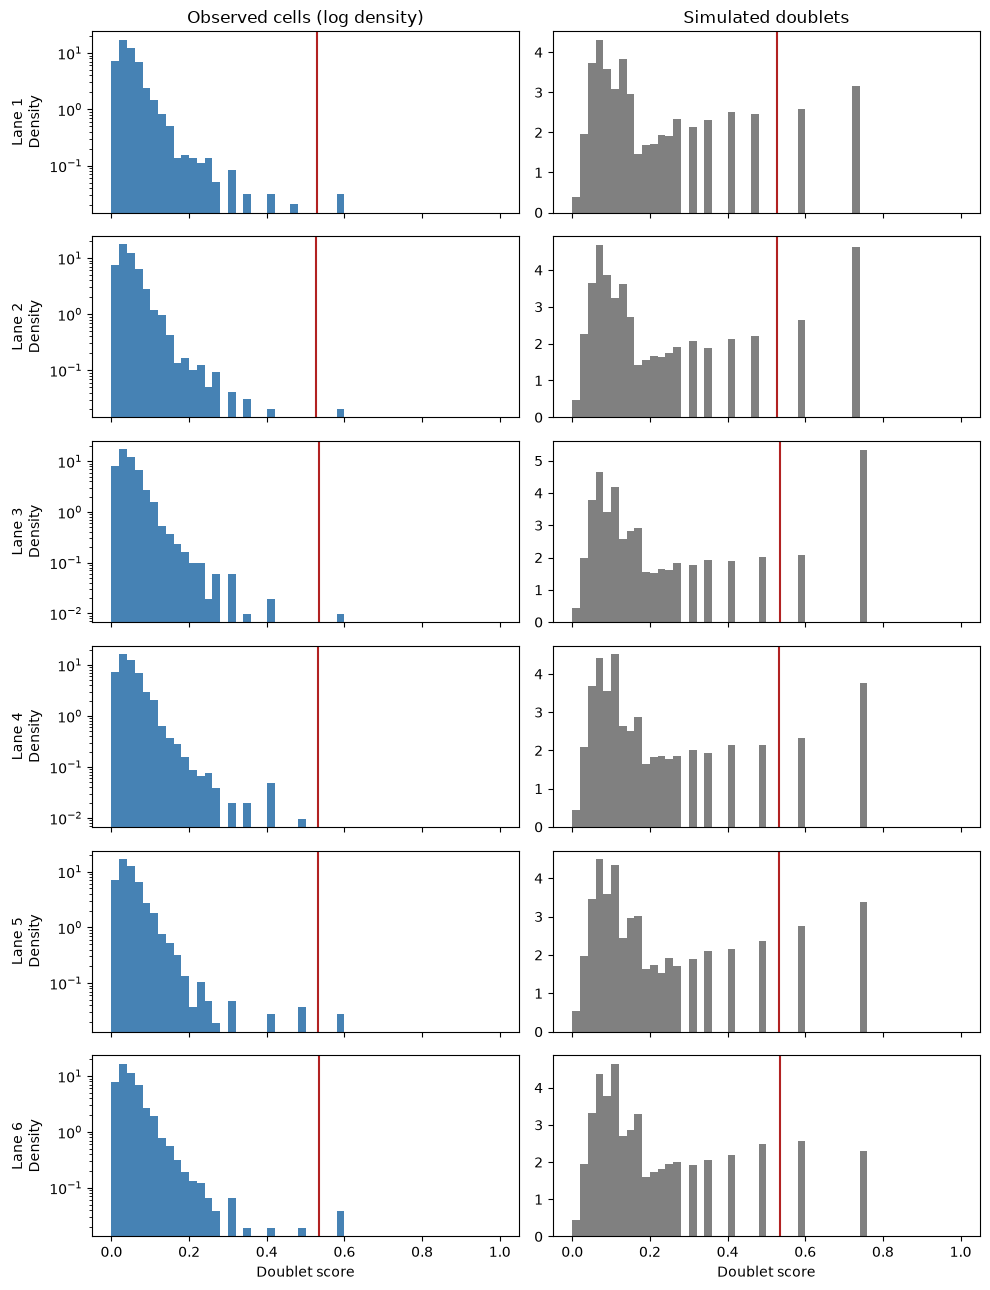

In [12]:
import matplotlib.pyplot as plt
import numpy as np

lane_order = sorted(scores_by_lane)
score_bins = np.linspace(0, 1, 51)

fig_doublet_scores, axes = plt.subplots(
    nrows=len(lane_order),
    ncols=2,
    figsize=(10, 13),
    sharex=True,
)

for row, lane in enumerate(lane_order):
    observed_ax, simulated_ax = axes[row]
    diagnostics = diagnostics_by_lane[lane]
    threshold = diagnostics["threshold"]

    observed_ax.hist(
        scores_by_lane[lane]["doublet_score"],
        bins=score_bins,
        density=True,
        log=True,
        color="steelblue",
    )

    simulated_ax.hist(
        diagnostics["doublet_scores_sim"],
        bins=score_bins,
        density=True,
        color="gray",
    )

    for ax in (observed_ax, simulated_ax):
        ax.axvline(threshold, color="firebrick", linewidth=1.5)

    observed_ax.set_ylabel(f"Lane {lane}\nDensity")

axes[0, 0].set_title("Observed cells (log density)")
axes[0, 1].set_title("Simulated doublets")
axes[-1, 0].set_xlabel("Doublet score")
axes[-1, 1].set_xlabel("Doublet score")

fig_doublet_scores.tight_layout()
plt.show()

In [13]:
lane_diagnostic_rows = []

for lane in lane_order:
    lane_scores = scores_by_lane[lane]
    diagnostics = diagnostics_by_lane[lane]
    threshold = diagnostics["threshold"]

    simulated_scores = np.asarray(
        diagnostics["doublet_scores_sim"]
    )
    flagged_cells = lane_scores["predicted_doublet"]

    lane_diagnostic_rows.append(
        {
            "Lane": lane,
            "n_cells": len(lane_scores),
            "threshold": threshold,
            "n_flagged": flagged_cells.sum(),
            "pct_observed_flagged": flagged_cells.mean() * 100,
            "pct_simulated_above_threshold": (
                (simulated_scores > threshold).mean() * 100
            ),
        }
    )

doublet_diagnostics = (
    pd.DataFrame(lane_diagnostic_rows)
    .set_index("Lane")
)

doublet_diagnostics.round(3)

,n_cells,threshold,n_flagged,pct_observed_flagged,pct_simulated_above_threshold
Lane,,,,,
1,4829,0.528,3,0.062,11.441
2,4935,0.526,2,0.041,14.509
3,5139,0.535,1,0.019,14.828
4,5169,0.533,0,0.000,12.188
5,5302,0.533,3,0.057,12.260
6,5302,0.535,4,0.075,9.723


In [14]:
qc_flag_overlap = pd.crosstab(
    qc_with_doublet_scores["preliminary_qc_flag"],
    qc_with_doublet_scores["predicted_doublet"],
    rownames=["Preliminary QC flag"],
    colnames=["Scrublet flag"],
    margins=True,
    margins_name="Total",
)

qc_flag_overlap

Scrublet flag,False,True,Total
Preliminary QC flag,,,
False,30576,13,30589
True,87,0,87
Total,30663,13,30676


In [15]:
qc_with_doublet_scores["qc_or_scrublet_flag"] = (
    qc_with_doublet_scores["preliminary_qc_flag"]
    | qc_with_doublet_scores["predicted_doublet"]
)

donor_flag_comparison = (
    qc_with_doublet_scores
    .groupby(["Donor", "condition"], observed=True)
    .agg(
        n_cells=("preliminary_qc_flag", "size"),
        n_preliminary_flags=("preliminary_qc_flag", "sum"),
        n_scrublet_flags=("predicted_doublet", "sum"),
        n_combined_flags=("qc_or_scrublet_flag", "sum"),
    )
)

donor_flag_comparison.sort_values(
    "n_scrublet_flags", ascending=False
)

,,n_cells,n_preliminary_flags,n_scrublet_flags,n_combined_flags
Donor,condition,,,,
UKERi1E4-R1-003,Control,3449,3,5,8
UKERiC99-R1-007,Parkinson,4591,4,3,7
UKERiR66-R1-007,Parkinson,2699,3,3,6
UKERi88H-R1-002,Parkinson,3288,9,2,11
UKERi1JF-R1-018,Control,1396,2,0,2
UKERi82A-R1-002,Control,869,12,0,12
UKERiAY6-R1-003,Parkinson,2997,12,0,12
UKERiG3G-R1-039,Control,3246,9,0,9
UKERiJ2C-R1-015,Parkinson,2191,20,0,20


In [16]:
qc_with_doublet_scores["keep_primary"] = (
    ~qc_with_doublet_scores["preliminary_qc_flag"]
)

qc_with_doublet_scores["keep_sensitivity"] = (
    qc_with_doublet_scores["keep_primary"]
    & ~qc_with_doublet_scores["predicted_doublet"]
)

retention_by_condition = (
    qc_with_doublet_scores
    .groupby("condition", observed=True)
    .agg(
        n_input=("keep_primary", "size"),
        n_primary=("keep_primary", "sum"),
        n_sensitivity=("keep_sensitivity", "sum"),
    )
)

print("Primary cells:", retention_by_condition["n_primary"].sum())
print("Sensitivity cells:", retention_by_condition["n_sensitivity"].sum())

retention_by_condition

Primary cells: 30589
Sensitivity cells: 30576


,n_input,n_primary,n_sensitivity
condition,,,
Control,11709,11680,11675
Parkinson,18967,18909,18901


In [17]:
primary_keep_mask = (
    qc_with_doublet_scores["keep_primary"].to_numpy(dtype=bool)
)
primary_cell_ids = adata.obs_names[primary_keep_mask]

primary_count_chunks = []

for counts_chunk, start, stop in adata.chunked_X(chunk_size=256):
    rows_to_keep = primary_keep_mask[start:stop]

    if rows_to_keep.any():
        retained_counts = counts_chunk[rows_to_keep, :]
        primary_count_chunks.append(sparse.csr_matrix(retained_counts))

primary_counts = sparse.vstack(primary_count_chunks, format="csr")
del primary_count_chunks

assert primary_counts.shape == (len(primary_cell_ids), adata.n_vars)

print("Primary count matrix shape:", primary_counts.shape)
print("Matrix format:", primary_counts.format)

Primary count matrix shape: (30589, 58735)
Matrix format: csr


In [18]:
qc_columns_to_keep = [
    "total_counts",
    "n_genes_by_counts",
    "total_counts_mt",
    "pct_counts_mt",
    "doublet_score",
    "predicted_doublet",
    "keep_sensitivity",
]

primary_obs = adata.obs.loc[primary_cell_ids].join(
    qc_with_doublet_scores.loc[primary_cell_ids, qc_columns_to_keep],
    validate="one_to_one",
)

primary_adata = ad.AnnData(
    X=primary_counts,
    obs=primary_obs,
    var=adata.var.copy(),
)

assert primary_adata.obs_names.equals(primary_cell_ids), (
    "Cell identifiers or order changed."
)

print("Filtered AnnData shape:", primary_adata.shape)
print("Donors retained:", primary_adata.obs["Donor"].nunique())
print("Sensitivity cells:", primary_adata.obs["keep_sensitivity"].sum())

Filtered AnnData shape: (30589, 58735)
Donors retained: 12
Sensitivity cells: 30576


In [19]:
interim_dir = project_root / "data" / "interim"
interim_dir.mkdir(parents=True, exist_ok=True)

output_path = interim_dir / "GSE176160_patients_qc.h5ad"
temporary_path = output_path.with_suffix(".tmp.h5ad")

primary_adata.write_h5ad(temporary_path, compression="gzip")

saved_adata = ad.read_h5ad(temporary_path, backed="r")

try:
    assert saved_adata.shape == primary_adata.shape
    assert saved_adata.obs_names.equals(primary_adata.obs_names)
    assert saved_adata.var_names.equals(primary_adata.var_names)
    assert saved_adata.obs["keep_sensitivity"].equals(
        primary_adata.obs["keep_sensitivity"]
    )
finally:
    saved_adata.file.close()

temporary_path.replace(output_path)

print("Verified shape:", primary_adata.shape)
print("Saved QC dataset:", output_path)

Verified shape: (30589, 58735)
Saved QC dataset: /Volumes/Amin's SSD/PhD_Projects/pd-nsc-scrna/data/interim/GSE176160_patients_qc.h5ad


In [20]:
tables_dir = project_root / "results" / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)

qc_with_doublet_scores.to_csv(
    tables_dir / "cell_qc_decisions.csv",
    index_label="cell_id",
)

doublet_diagnostics.to_csv(
    tables_dir / "scrublet_diagnostics_by_lane.csv"
)

retention_by_condition.to_csv(
    tables_dir / "qc_retention_by_condition.csv"
)

donor_flag_comparison.to_csv(
    tables_dir / "qc_flag_comparison_by_donor.csv"
)

print("Cell decisions saved:", len(qc_with_doublet_scores))
print("QC tables saved to:", tables_dir)

Cell decisions saved: 30676
QC tables saved to: /Volumes/Amin's SSD/PhD_Projects/pd-nsc-scrna/results/tables


In [21]:
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

for extension in ["png", "pdf"]:
    figure_path = figures_dir / f"qc_scrublet_scores_by_lane.{extension}"

    fig_doublet_scores.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    print("Saved figure:", figure_path.name)

Saved figure: qc_scrublet_scores_by_lane.png
Saved figure: qc_scrublet_scores_by_lane.pdf


## Quality control outcome

The primary filter excluded 87 of 30,676 input cells using two criteria: fewer than 1,000 detected genes or a mitochondrial count fraction of at least 15%. The filtered count matrix contains 30,589 cells and 58,735 genes. All 12 donors were retained.

Scrublet was run separately for each of the six lanes with an expected doublet rate of 0.05 and automatic score thresholds. It flagged 13 additional cells. These cells were retained in the primary dataset and marked for exclusion in the sensitivity analysis, which retains 30,576 cells.

The primary count matrix was saved as `data/interim/GSE176160_patients_qc.h5ad`. Cell-level decisions and summaries by lane, donor, and disease group are available in `results/tables/`.